# 4. Zementauslaugung

**Ziel.** Minerale in die Säule bringen und reagieren lassen. Eine 4 mm dicke hydratisierte Zementpaste steht 1000 Jahre in Kontakt mit CaCl₂-Wasser: Ca diffundiert
hinaus, Portlandit löst sich von der Oberfläche nach innen, und hinter der Front entkalkt C-S-H. Das ist die Abfolge des
[Ca/Si-Scans aus Tutorial 2](02_single_equilibrium.ipynb), jetzt als Funktion der Tiefe.

Neu in `case.yaml`:

- **`solid_phases`** mit echten Mineralen und `gibbs`-Anpassungen aus dem Benchmark;
- **ein `inlet`-Rezept** am linken `dirichlet`-Rand und ein `no_flux`-Rand rechts;
- **lange Zeiten**: `dt` = 0,1 Jahr und `end` = 1000 Jahre, beide in Sekunden;
- **Rückkopplungsschalter**: Der Benchmark hält φ und De konstant; am Ende schalten wir sie ein.

| | |
|---|---|
| Modus | `coupled` |
| Fallordner | `FEniCSx_GEMS/example/demo_Cement_1D_benchmark` (dieses Notebook läuft dort) |
| Gebiet | 4 mm, 40 Zellen, 10 000 Schritte |
| Laufzeit | etwa 5 min pro Lauf; 400 000 GEMS-Gleichgewichte |
| Referenz | HYDRUS-Profile desselben Benchmarks, `Profile_HYDRUS.out` |

In [1]:
print(open('case.yaml').read())

# EURAD HERMES cement benchmark (Cement_1D_ReactiveTransport_SNIA_doc.ipynb),
# reproduced with the four modules in the parent folder.
# Run from this folder:  python ../../coupling.py case.yaml   (or use the notebook)
#
# Benchmark: L = 4 mm, porosity 0.5 (500 g water per dm3 bulk), Dp = 1e-14 m2/s,
# 25 C, left boundary = Cox-type water (CaCl2, pH ~7.6), right boundary closed,
# constant porosity and diffusivity, profiles every 100 years up to 1000 years.

# 1. chemistry.py: GEMS project, chemical conditions, and recipes.
chemistry:
  project: ../../chemistry_data/b_time0-dat.lst   # relative to this case.yaml
  temperature: 298.15                  # K (25 C)
  pressure: 100000                     # Pa
  aqueous_phase: aq_gen
  solid_phases: [CSHQ, Portlandite, Silica-amorph]

  # Gibbs energy adjustments used by the benchmark notebook (J/mol).
  gibbs: {H2O@: -237183.0, Ca+2: -552400.0}

  # Sample: element amounts in mol per 1 dm3 of BULK sample (pore water + solids).
  # CaO 1.11 

Zu den Zahlen:

- `project: ../../chemistry_data/b_time0-dat.lst`: Dieser Fall verwendet das GEMS-Projekt im Hauptordner, dasselbe wie Tutorial 2.
- `De: 5.0e-15` ist $\phi D_p$ mit dem Porendiffusionskoeffizienten des Benchmarks $D_p = 10^{-14}$ m²/s.
- `dt: 3155760` s sind 0,1 Jahre. Mit $D_p\,\Delta t/h^2 \approx 3$ wäre ein explizites Verfahren instabil, das implizite Euler-Verfahren nicht.
- `every: 1000` schreibt alle 100 Jahre ein Profil.

## Rechnen

Der Fortschritt wird alle 1000 Schritte ausgegeben.

In [2]:
import time
t0 = time.time()
!python ../../coupling.py case.yaml 2>&1 | grep -v gems3k | grep -E "step=.*000,|Saved"
print(f'{(time.time() - t0) / 60:.1f} min')

step=1000, time=3.15576e+09 s, balance=3.633e-11 mol/m2, chemistry=8.158e-08 mol/m3, water mismatch=0.03%
step=2000, time=6.31152e+09 s, balance=7.255e-11 mol/m2, chemistry=7.872e-08 mol/m3, water mismatch=0.03%
step=3000, time=9.46728e+09 s, balance=1.091e-10 mol/m2, chemistry=5.490e-07 mol/m3, water mismatch=0.03%
step=4000, time=1.2623e+10 s, balance=1.460e-10 mol/m2, chemistry=1.046e-06 mol/m3, water mismatch=0.03%
step=5000, time=1.57788e+10 s, balance=1.826e-10 mol/m2, chemistry=7.324e-08 mol/m3, water mismatch=0.03%
step=6000, time=1.89346e+10 s, balance=2.190e-10 mol/m2, chemistry=1.127e-07 mol/m3, water mismatch=0.03%
step=7000, time=2.20903e+10 s, balance=2.550e-10 mol/m2, chemistry=2.005e-07 mol/m3, water mismatch=0.03%
step=8000, time=2.52461e+10 s, balance=2.916e-10 mol/m2, chemistry=1.070e-07 mol/m3, water mismatch=0.03%
step=9000, time=2.84018e+10 s, balance=3.282e-10 mol/m2, chemistry=5.059e-07 mol/m3, water mismatch=0.03%
step=10000, time=3.15576e+10 s, balance=3.645e-

4.5 min


In [3]:
print(open('results_benchmark/summary.txt').read())

COMPLETED
Mode: coupled
Cells/states: 40; reference length: 0.004 m
Scheme: backward Euler, DG0 two-point cell flux (transport modes only)
Linear solver: preonly / lu
Final time: 31557600000.0 s; steps: 10000
Amounts: mol/m3 bulk; concentrations: mol/m3 pore water
Inventory and boundary exchange: mol/m2 (unit cross-sectional area)
Maximum balance error: 3.645013e-10 mol/m2
Maximum chemical element reconstruction error: 5.382091e-04 mol/m3
Maximum aqueous-volume/porosity mismatch: 0.253729%
GEMS initialisation: independent cold start for every equilibrium call
Final porosity range: 0.5 to 0.5
Final De range: 5e-15 to 5e-15 m2/s
Porosity feedback: False
Diffusivity feedback: False
Limit: numerical demonstration, not experimental validation.
Limit: saturated pore volume is assumed; aqueous volume mismatch is diagnostic only.



## Das ausgelaugte Profil

Mineralmengen sind in mol pro m³ Gesamtvolumen; durch 1000 geteilt ergibt mol/dm³.

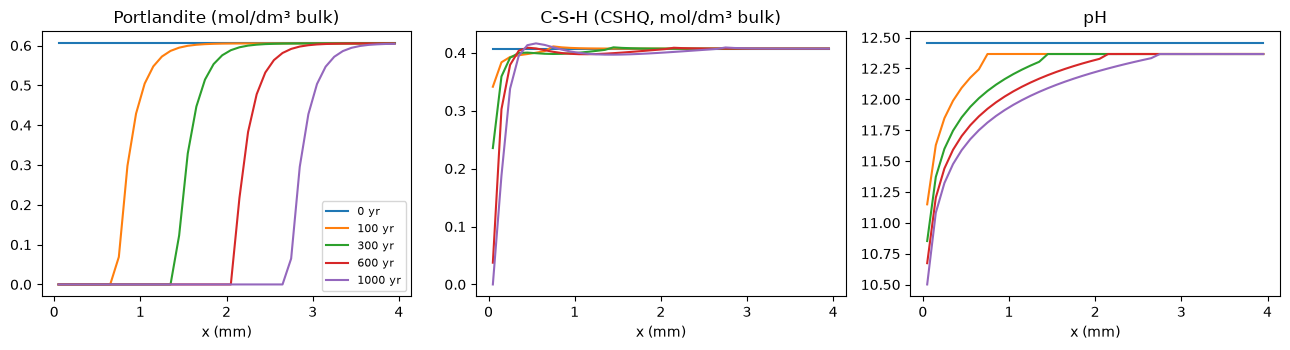

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
YEAR = 365.25 * 86400
p = pd.read_csv('results_benchmark/profiles.csv')
p['t_yr'] = (p.time_s / YEAR).round(3)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for t, g in p.groupby('t_yr'):
    if t in (0, 100, 300, 600, 1000):
        g = g.sort_values('x_m')
        axes[0].plot(g.x_m * 1e3, g.Portlandite_mol_m3_bulk / 1000, label=f'{t:g} yr')
        axes[1].plot(g.x_m * 1e3, g.CSHQ_mol_m3_bulk / 1000)
        axes[2].plot(g.x_m * 1e3, g.pH)
axes[0].set(title='Portlandite (mol/dm³ bulk)', xlabel='x (mm)'); axes[0].legend(fontsize=8)
axes[1].set(title='C-S-H (CSHQ, mol/dm³ bulk)', xlabel='x (mm)')
axes[2].set(title='pH', xlabel='x (mm)')
plt.tight_layout(); plt.show()

Portlandit verschwindet in einer wachsenden Zone an der Oberfläche, mit scharfer Front. Dahinter fällt der pH von etwa 12,5 auf unter 12, und C-S-H verliert Ca.

## Vergleich mit dem HYDRUS-Benchmark

`Profile_HYDRUS.out` gibt alles pro dm³ Gesamtmaterial an, deshalb wird die Modellausgabe umgerechnet:

$$
X_\text{aq} = \frac{\phi\,c_X}{1000},\qquad X_\text{s} = \frac{\text{total}_X - \phi\,c_X}{1000},\qquad
\text{Ca}_\text{ss} = \text{Ca}_\text{s} - \text{Portlandit}
$$

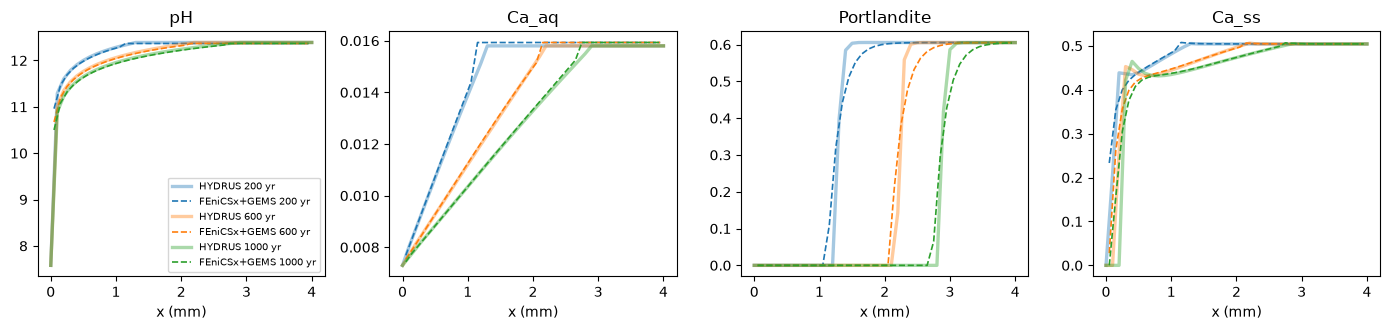

,pH,Ca_aq,Portlandite,Ca_ss
t (yr),,,,
200,2.38e-02,2.02e-04,4.14e-02,1.75e-02
600,2.50e-02,9.63e-05,4.10e-02,2.79e-02
1000,2.62e-02,1.23e-04,3.89e-02,4.26e-02


In [5]:
sim = pd.DataFrame({'Time': p.t_yr, 'Distance': p.x_m, 'pH': p.pH})
for n in ('Ca', 'Si'):
    aq = p[f'{n}_c_mol_m3_water'] * p.phi
    sim[f'{n}_aq'] = aq / 1000
    sim[f'{n}_s'] = (p[f'{n}_total_mol_m3_bulk'] - aq) / 1000
sim['Portlandite'] = p.Portlandite_mol_m3_bulk / 1000
sim['Ca_ss'] = sim.Ca_s - sim.Portlandite
bench = pd.read_csv('Profile_HYDRUS.out', sep=r'\s+')
bench = bench.loc[:, ~bench.columns.str.startswith('Unnamed')]

cols = ['pH', 'Ca_aq', 'Portlandite', 'Ca_ss']
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for k, t in enumerate((200, 600, 1000)):
    b = bench[np.isclose(bench.Time, t)].sort_values('Distance')
    s = sim[np.isclose(sim.Time, t)].sort_values('Distance')
    for ax, c in zip(axes, cols):
        ax.plot(b.Distance * 1e3, b[c], '-', lw=2.4, alpha=0.4, color=f'C{k}', label=f'HYDRUS {t} yr')
        ax.plot(s.Distance * 1e3, s[c], '--', lw=1.2, color=f'C{k}', label=f'FEniCSx+GEMS {t} yr')
for ax, c in zip(axes, cols):
    ax.set(title=c, xlabel='x (mm)')
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

rows = []   # RMS over the reference nodes inside the paste (x > 0; x = 0 is the boundary water in the reference)
for t in (200, 600, 1000):
    b = bench[np.isclose(bench.Time, t) & (bench.Distance > 0)].sort_values('Distance')
    s = sim[np.isclose(sim.Time, t)].sort_values('Distance')
    rows.append({'t (yr)': t, **{c: np.sqrt(np.mean((np.interp(b.Distance, s.Distance, s[c]) - b[c]) ** 2)) for c in cols}})
pd.DataFrame(rows).set_index('t (yr)').style.format('{:.2e}')

Dicke Linien sind HYDRUS, gestrichelte dieses Modell. Beide Codes setzen die Portlanditfront bis auf etwa eine Zelle (0,1 mm) an dieselbe Stelle. Die Tabelle gibt die
RMS-Abweichung an den Referenzknoten innerhalb der Paste, in den Einheiten jeder Spalte. Der Knoten bei x = 0 fehlt, weil die Referenz dort das Randwasser selbst speichert (pH 7,6),
während der erste Wert dieses Modells im Mittelpunkt der ersten Zelle liegt.
Die verbleibenden Unterschiede kommen von den verschiedenen Gittern (die Referenz speichert Werte an Knoten, einschließlich des Randknotens; hier liegt der Rand eine halbe Zelle vom ersten
Zellmittelpunkt entfernt), der Zeitschrittweite und Rundung in GEMS.

Unter Diffusionskontrolle wandert die Front mit $\sqrt{t}$:

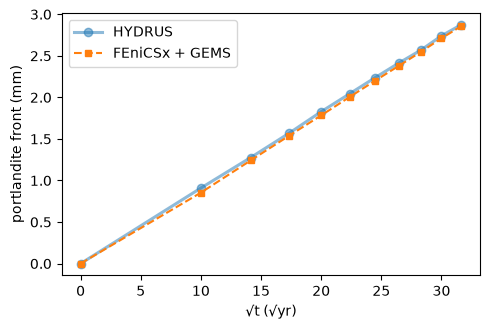

In [6]:
def front(df, t, frac=0.5):
    d = df[np.isclose(df.Time, t)].sort_values('Distance')
    f = d.Portlandite.to_numpy() / df[np.isclose(df.Time, 0)].Portlandite.max()
    i = np.argmax(f >= frac)
    if i == 0:
        return 0.0
    x = d.Distance.to_numpy()
    return (x[i - 1] + (frac - f[i - 1]) / (f[i] - f[i - 1]) * (x[i] - x[i - 1])) * 1e3

times = np.array(sorted(set(sim.Time) & set(bench.Time)))
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(np.sqrt(times), [front(bench, t) for t in times], 'o-', alpha=0.5, lw=2.2, label='HYDRUS')
ax.plot(np.sqrt(times), [front(sim, t) for t in times], 's--', ms=4, label='FEniCSx + GEMS')
ax.set(xlabel='√t (√yr)', ylabel='portlandite front (mm)'); ax.legend(); plt.tight_layout(); plt.show()

## Rückkopplung von Porosität und Diffusivität einschalten

Der Benchmark hält φ und De fest. In Wirklichkeit öffnet sich lösender Portlandit die Poren, und in der ausgelaugten Zone wird die Diffusion schneller. Zwei Zeilen in
`case.yaml` schalten das ein. Wir schreiben eine Kopie mit neuem Ausgabeordner:

```yaml
coupling:
  update_porosity: true      # phi = phi0 + V_solid0 - V_solid
  update_diffusivity: true   # De = De0 (phi/phi0)^2
output:
  folder: results_feedback
```

In [7]:
import yaml
case = yaml.safe_load(open('case.yaml'))
case['coupling']['update_porosity'] = True
case['coupling']['update_diffusivity'] = True
case['output']['folder'] = 'results_feedback'
yaml.safe_dump(case, open('case_feedback.yaml', 'w'), sort_keys=False)
!python ../../coupling.py case_feedback.yaml 2>&1 | grep -v gems3k | grep -E "Saved"

Saved: /home/claude/fg_book/_build_src/work/FEniCSx_GEMS/example/demo_Cement_1D_benchmark/results_feedback


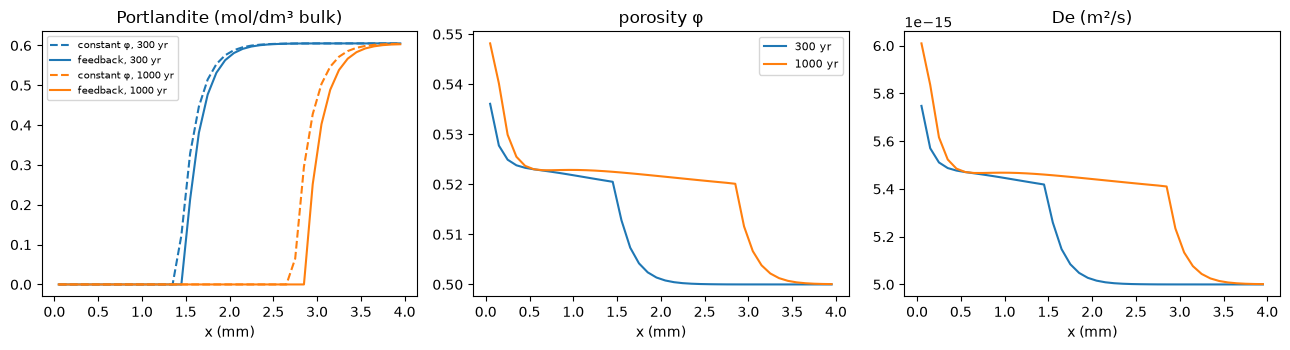

 range: 0.500068837 to 0.548162363
Final De range: 5.00137683e-15 to 6.00963953e-15 m2/s
Porosity feedback: True
Diffusi


In [8]:
q = pd.read_csv('results_feedback/profiles.csv'); q['t_yr'] = (q.time_s / YEAR).round(3)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for k, t in enumerate((300, 1000)):
    a = p[np.isclose(p.t_yr, t)].sort_values('x_m'); b = q[np.isclose(q.t_yr, t)].sort_values('x_m')
    axes[0].plot(a.x_m * 1e3, a.Portlandite_mol_m3_bulk / 1000, '--', color=f'C{k}', label=f'constant φ, {t} yr')
    axes[0].plot(b.x_m * 1e3, b.Portlandite_mol_m3_bulk / 1000, '-', color=f'C{k}', label=f'feedback, {t} yr')
    axes[1].plot(b.x_m * 1e3, b.phi, color=f'C{k}', label=f'{t} yr')
    axes[2].plot(b.x_m * 1e3, b.De_m2_s, color=f'C{k}')
axes[0].set(title='Portlandite (mol/dm³ bulk)', xlabel='x (mm)'); axes[0].legend(fontsize=7)
axes[1].set(title='porosity φ', xlabel='x (mm)'); axes[1].legend(fontsize=8)
axes[2].set(title='De (m²/s)', xlabel='x (mm)')
plt.tight_layout(); plt.show()
print(open('results_feedback/summary.txt').read().split('Final porosity')[1][:120])

Die Lösung erhöht φ nahe der Oberfläche von 0,50 auf etwa 0,55, und De steigt mit $(\phi/\phi_0)^2$ um etwa 20 %. Die Wirkung auf die Front ist hier klein und geht in die
unerwartete Richtung: Die Portlanditfront liegt etwa 0,1 mm *hinter* dem Lauf mit konstanten Eigenschaften. Portlandit füllt nur wenige Prozent des Volumens, φ ändert sich also wenig,
und die ausgelaugte Zone enthält nun auch mehr Porenwasser. Solche Effekte mit einem Lauf prüfen, statt sie anzunehmen. Der Exponent ist eine Modellannahme, keine Eigenschaft der Paste.

## Selbst ausprobieren

1. `dt` halbieren und die Frontlage nach 1000 Jahren vergleichen: Ist der Zeitschritt klein genug?
2. 80 statt 40 Zellen verwenden.
3. Das Zustromwasser durch reines Wasser ersetzen: Ca, Cl und Si aus `inlet` entfernen (Spuren `1.0e-15` behalten).
4. Im Rückkopplungslauf `exponent: 3.0` setzen.

**Weiter:** [Tutorial 5](05_calcite_dolomite.ipynb) fügt Strömung hinzu.